# 02 How many respondents do we need?
**Chapter 3: Methodology — D4 Sample size.** The Python twin of `02_sample_size.do`.

1. Reproduce the Krejcie & Morgan (1970) table from its formula.
2. Show that the margin of error matters more than the population size.
3. Run a priori power analyses (two groups; multiple regression), matching Stata and G*Power.

In [1]:
# Setup: install anything missing (needed on Google Colab), then load the libraries.
import importlib.util, subprocess, sys
for pkg in ["pandas", "numpy", "scipy", "statsmodels", "linearmodels", "matplotlib", "openpyxl"]:
    if importlib.util.find_spec(pkg) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=True)

from pathlib import Path
import numpy as np
import pandas as pd

pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 30)

# Data live in ../data next to this notebook; online (e.g. Colab) they are read from GitHub.
DATA = Path("../data")
RAW_URL = "https://raw.githubusercontent.com/soonjanjan-lang/Chapter3-Methodology-lectnotes-dashboard/main/downloads/data/"

def load(name):
    p = DATA / name
    return pd.read_csv(p) if p.exists() else pd.read_csv(RAW_URL + name)

In [2]:
from scipy import stats
import matplotlib.pyplot as plt

def km_size(N, d=0.05, P=0.5, level=0.95):
    """Krejcie & Morgan (1970): s = X2 N P(1-P) / [d2 (N-1) + X2 P(1-P)]."""
    chi2 = stats.chi2.ppf(level, 1)                       # 3.841 at 95%
    return chi2 * N * P * (1 - P) / (d**2 * (N - 1) + chi2 * P * (1 - P))

tab = pd.DataFrame({"N": [100, 1000, 9000, 10000, 50000, 1_000_000]})
tab["exact s"] = tab["N"].map(km_size).round(2)
tab["table value"] = tab["exact s"].round().astype(int)
tab

,N,exact s,table value
0,100,79.51,80
1,1000,277.73,278
2,9000,368.46,368
3,10000,369.97,370
4,50000,381.22,381
5,1000000,384.00,384


## The curve flattens: beyond about 10,000 the population size hardly matters

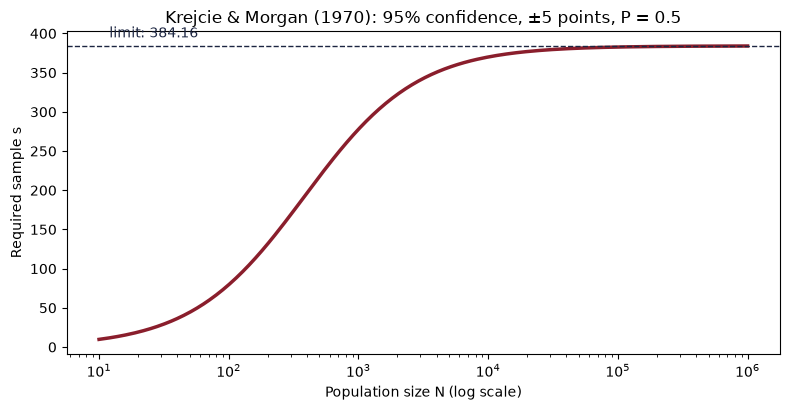

In [3]:
Ns = np.unique(np.round(np.logspace(1, 6, 200)))
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.plot(Ns, [km_size(x) for x in Ns], color="#8A1E2C", lw=2.5)
ax.axhline(384.16, color="#1C2541", ls="--", lw=1)
ax.set_xscale("log"); ax.set_xlabel("Population size N (log scale)"); ax.set_ylabel("Required sample s")
ax.set_title("Krejcie & Morgan (1970): 95% confidence, ±5 points, P = 0.5")
ax.text(12, 395, "limit: 384.16", color="#1C2541")
plt.tight_layout(); plt.show()

## The margin of error changes the answer (N = 10,000)

In [4]:
pd.DataFrame({"margin d": [0.03, 0.05, 0.10],
              "required n (rounded up)": [int(np.ceil(km_size(10000, d))) for d in (0.03, 0.05, 0.10)]})

,margin d,required n (rounded up)
0,0.03,965
1,0.05,370
2,0.10,96


In [5]:
n0 = stats.norm.ppf(0.975)**2 * 0.25 / 0.05**2
print(f"Infinite population: n0 = {n0:.2f}")
print("Invite", int(np.ceil(370 / 0.60)), "people to obtain 370 responses at a 60% response rate")
deff = 1 + (20 - 1) * 0.025
print(f"Design effect = {deff:.2f}; effective n of 384 = {384 / deff:.1f}")

Infinite population: n0 = 384.15
Invite 617 people to obtain 370 responses at a 60% response rate
Design effect = 1.48; effective n of 384 = 260.3


## Power for comparing two groups of 185 (two-sided t-test, α = 0.05)

In [6]:
from statsmodels.stats.power import TTestIndPower
tt = TTestIndPower()
for d in (0.2, 0.3, 0.5):
    print(f"d = {d}: power = {tt.power(effect_size=d, nobs1=185, ratio=1, alpha=0.05):.4f}")
n_per_group = int(np.ceil(tt.solve_power(effect_size=0.2, power=0.8, alpha=0.05, ratio=1)))
print("n per group for 80% power at d = 0.2:", n_per_group)

d = 0.2: power = 0.4835
d = 0.3: power = 0.8206
d = 0.5: power = 0.9977
n per group for 80% power at d = 0.2: 394


## Power for multiple regression (F test that all slopes are zero)
Noncentral F with λ = f² N, numerator df u = number of predictors, denominator df N − u − 1 (as in G*Power).

In [7]:
def reg_power(N, f2, u, alpha=0.05):
    v = N - u - 1
    crit = stats.f.ppf(1 - alpha, u, v)
    return 1 - stats.ncf.cdf(crit, u, v, f2 * N)

def reg_n(f2, u, power=0.8, alpha=0.05):
    N = u + 3
    while reg_power(N, f2, u, alpha) < power:
        N += 1
    return N

print("f2 = 0.15, 5 predictors, 80% power: N =", reg_n(0.15, 5))

f2 = 0.15, 5 predictors, 80% power: N = 92


For one tested coefficient with controls the numerator df is the number of tested
predictors (1) and the denominator df is N − (controls + tested) − 1.

In [8]:
def reg_n_subset(f2, tested, controls, power=0.8, alpha=0.05):
    N = tested + controls + 3
    while True:
        v = N - tested - controls - 1
        crit = stats.f.ppf(1 - alpha, tested, v)
        if 1 - stats.ncf.cdf(crit, tested, v, f2 * N) >= power:
            return N
        N += 1

print("partial f2 = 0.02, 1 tested coefficient, 7 controls: N =", reg_n_subset(0.02, 1, 7))

partial f2 = 0.02, 1 tested coefficient, 7 controls: N = 395


## Worked example in D4: the e-wallet survey

In [9]:
print(round(km_size(10000)))                          # 370
print(reg_n_subset(0.02, tested=1, controls=7))       # 395
print(int(np.ceil(395 / 0.60)))                       # 659 invitations

370
395
659


In [10]:
assert reg_n_subset(0.02, tested=1, controls=7) == 395
assert tab["table value"].tolist() == [80, 278, 368, 370, 381, 384]
assert reg_n(0.15, 5) == 92 and n_per_group == 394
print("Matches the Krejcie–Morgan table, Stata's power command and G*Power.")

Matches the Krejcie–Morgan table, Stata's power command and G*Power.